# Building 3 — electricity demand forecasting (improved)

This notebook replaces the earlier `building3.ipynb`. It runs top to bottom as **one clean pipeline**:

| Step | What happens | What changed from the old notebook |
|---|---|---|
| 1 | Load Building 3 (15-min) and ERA5 weather | Works from `phase_1_data.csv` **or** the original `.tsf` |
| 2 | Clean the target and resample to hourly | Hours with fewer than 3 of 4 readings are dropped; the 8,556 spike after a data gap is masked |
| 3 | Calendar features | Same semester / exam / holiday / COVID rules, plus hour-of-week and holiday-distance features |
| 4 | Weather features | **Timezone bug fixed** — ERA5 is in UTC, the meter is in Melbourne local time (solar now peaks at 1 pm, not 3 am) |
| 5 | Build the modelling table for a chosen **forecast horizon** | Only uses demand history that would actually be known at forecast time (no `lag_1h` leak for a 24 h forecast) |
| 6 | Baselines | Naive forecasts scored on **the same folds** as the models |
| 7 | Compare 9 models with walk-forward cross-validation | 5 time-ordered test windows instead of one 80/20 split; scale-sensitive models get a scaled target |
| 8 | Tune XGBoost (the best model) | Tuned only on data *before* every test window, so the scores stay honest |
| 9 | Accuracy report, skill score, error analysis | Breakdowns by hour, weekday, month and COVID vs pre-COVID |
| 10 | Prediction intervals | Conformal 80 % bands, with their measured coverage |
| 11 | Weather sensitivity | How much accuracy depends on knowing the weather in advance |
| 12 | Explaining the model | SHAP feature effects |
| 13 | Final model + forecast for the next horizon | Trained on all data and saved |

**Change `HORIZON_HOURS` in the configuration cell** to match your project brief (e.g. `24` for day-ahead, `168` for week-ahead, `720` for month-ahead). Everything else adapts automatically.

## 0. Configuration

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=UserWarning)

# ---- What to forecast ------------------------------------------------------
BUILDING = "Building3"
HORIZON_HOURS = 24            # how far ahead each forecast is made (24 = day-ahead)
MIN_READINGS_PER_HOUR = 3     # an hour needs at least 3 of its 4 15-min readings
N_CV_FOLDS = 5                # walk-forward test windows
RANDOM_STATE = 42

# ---- Where the data lives --------------------------------------------------
# The first folder in this list that exists is used. Put your own folder first.
CANDIDATE_DATA_DIRS = [
    Path(r"C:\Users\Coder\Desktop\ADS2002\Monash Solar Farm Project Data-20260814\MonashSolarFarm"),
    Path.cwd() / "data",
    Path.cwd(),
]
DATA_DIR = next((p for p in CANDIDATE_DATA_DIRS if p.exists()), Path.cwd())
DEMAND_CSV = DATA_DIR / "phase_1_data.csv"
DEMAND_TSF = DATA_DIR / "phase_1_data.tsf"
WEATHER_CSV = DATA_DIR / "ERA5_Weather_Data_Monash.csv"

OUTPUT_DIR = Path.cwd() / "building3_improved_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# ---- Chart style -------------------------------------------------------------
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BASELINE_GREY = "#a3a29c"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 1.6,
})

print("Data folder :", DATA_DIR)
print("Horizon     :", HORIZON_HOURS, "hours ahead")

Data folder : /home/pyodide
Horizon     : 24 hours ahead


## 1. Load the data

Building 3 is read from `phase_1_data.csv` if it exists, otherwise from the original `phase_1_data.tsf`. Only the readings after the building's real start time are used, so no padded zeros enter the data.

In [2]:
def load_from_tsf(path, series_name):
    # Minimal .tsf reader for one series (format: name:start_timestamp:v1,v2,...).
    with open(path, encoding="cp1252") as f:
        in_data = False
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            if line.lower().startswith("@data"):
                in_data = True
                continue
            if in_data and line.startswith(series_name + ":"):
                name, start, values = line.split(":", 2)
                start = pd.to_datetime(start, format="%Y-%m-%d %H-%M-%S")
                vals = [np.nan if v == "?" else float(v) for v in values.split(",")]
                idx = pd.date_range(start, periods=len(vals), freq="15min")
                return pd.Series(vals, index=idx, name=series_name)
    raise ValueError(f"{series_name} not found in {path}")


if DEMAND_CSV.exists():
    raw = pd.read_csv(DEMAND_CSV, usecols=["timestamp", BUILDING], parse_dates=["timestamp"])
    raw_15min = raw.set_index("timestamp")[BUILDING].astype(float)
    source = DEMAND_CSV.name
else:
    raw_15min = load_from_tsf(DEMAND_TSF, BUILDING)
    source = DEMAND_TSF.name

# Start at the first real (non-zero, non-missing) reading.
first_real = raw_15min[(raw_15min > 0)].index.min()
raw_15min = raw_15min.loc[first_real:].asfreq("15min")

print(f"Source           : {source}")
print(f"Period           : {raw_15min.index.min()}  ->  {raw_15min.index.max()}")
print(f"15-min readings  : {raw_15min.notna().sum():,}  (missing: {raw_15min.isna().sum():,})")
print(raw_15min.describe().round(1).to_string())

Source           : phase_1_data.csv
Period           : 2016-03-01 04:15:00  ->  2020-09-30 23:45:00
15-min readings  : 160,222  (missing: 561)
count    160222.0
mean        517.9
std         273.8
min          85.0
25%         308.0
50%         392.0
75%         723.0
max        8556.0


## 2. Clean the target and resample to hourly

* An hour is kept only if at least `MIN_READINGS_PER_HOUR` of its four 15-minute readings exist, so one stray reading cannot stand in for a whole hour.
* The first reading after a data gap is checked for meter "catch-up" spikes (more than 6 × the median). These are set to missing, not deleted, so they simply drop out like any other gap.
* The target is **never** filled in. Imputing demand would create fake labels and make the accuracy look better than it is.

In [3]:
counts = raw_15min.resample("1h").count()
hourly = raw_15min.resample("1h").mean().where(counts >= MIN_READINGS_PER_HOUR)

gap_edge = hourly.notna() & hourly.shift(1).isna()
spike = hourly > hourly.median() * 6
flagged = hourly[gap_edge & spike]
usage = hourly.mask(gap_edge & spike).rename("usage")   # regular hourly index, NaN = unknown

print(f"Hours in period         : {len(usage):,}")
print(f"Hours kept              : {usage.notna().sum():,}")
print(f"Hours dropped (<{MIN_READINGS_PER_HOUR}/4)    : {(counts.between(1, MIN_READINGS_PER_HOUR - 1)).sum():,}")
print(f"Hours with no data      : {(counts == 0).sum():,}")
print(f"Spikes masked after gaps: {len(flagged)}")
display(flagged.round(1).to_frame("masked value"))

Hours in period         : 40,196
Hours kept              : 40,057
Hours dropped (<3/4)    : 8
Hours with no data      : 130
Spikes masked after gaps: 1


,masked value
timestamp,
2017-04-12 04:00:00,8556.0


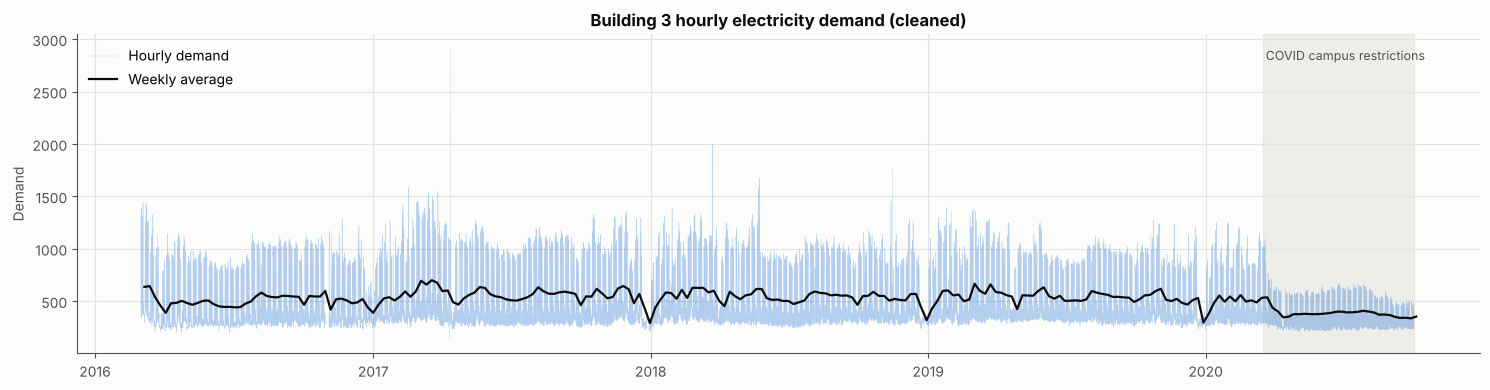

In [4]:
fig, ax = plt.subplots(figsize=(15, 4))
weekly = usage.resample("W").mean()
ax.plot(usage.index, usage, color=BLUE, linewidth=0.3, alpha=0.35, label="Hourly demand")
ax.plot(weekly.index, weekly, color=INK, linewidth=1.6, label="Weekly average")
ax.axvspan(pd.Timestamp("2020-03-16"), usage.index.max(), color=GRID, alpha=0.6, zorder=0)
ax.text(pd.Timestamp("2020-03-20"), ax.get_ylim()[1] * 0.92, "COVID campus restrictions", color=INK_2, fontsize=9)
ax.set_title("Building 3 hourly electricity demand (cleaned)")
ax.set_ylabel("Demand")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 3. Calendar features

The semester, exam, holiday and COVID date ranges are the same as in the supplied `FEATURES_CODE.ipynb`. They are now calculated directly on the hourly timestamps, which gives the same values as the old "15-minute then `max()`" approach.

New features:
* `hour`, `dayofweek`, `hour_of_week` — campus demand repeats on a weekly cycle.
* `month_sin/cos`, `doy_sin/cos` — smooth seasonal position.
* `days_to_holiday`, `days_since_holiday` — demand often dips around long weekends.

Exact duplicates (`is_weekend`, `university_closed`, `semester_active`) are left out because they are 1 minus another column.

In [5]:
UNIVERSITY_OPEN = [("2016-01-04", "2016-12-22"), ("2017-01-03", "2017-12-21"), ("2018-01-02", "2018-12-21"),
                   ("2019-01-02", "2019-12-23"), ("2020-01-02", "2020-12-23")]
SEMESTER_1 = [("2016-02-29", "2016-05-27"), ("2017-02-21", "2017-05-26"), ("2018-02-26", "2018-05-25"),
              ("2019-03-04", "2019-05-31"), ("2020-03-09", "2020-06-12")]
SEMESTER_2 = [("2016-07-25", "2016-10-21"), ("2017-07-24", "2017-10-20"), ("2018-07-23", "2018-10-19"),
              ("2019-07-29", "2019-10-25"), ("2020-08-03", "2020-11-06")]
MID_SEM_BREAK = [("2016-03-25", "2016-04-01"), ("2016-09-26", "2016-09-30"), ("2017-04-14", "2017-04-21"),
                 ("2017-09-25", "2017-09-29"), ("2018-03-30", "2018-04-06"), ("2018-09-24", "2018-09-28"),
                 ("2019-04-19", "2019-04-26"), ("2019-09-30", "2019-10-04"), ("2020-04-10", "2020-04-17"),
                 ("2020-09-21", "2020-10-02")]
ORIENTATION = [("2016-02-22", "2016-02-26"), ("2016-07-18", "2016-07-22"), ("2017-02-20", "2017-02-24"),
               ("2017-07-17", "2017-07-21"), ("2018-02-19", "2018-02-23"), ("2018-07-16", "2018-07-20"),
               ("2019-02-25", "2019-03-01"), ("2019-07-22", "2019-07-26"), ("2020-07-27", "2020-07-31")]
SWOTVAC = [("2016-05-30", "2016-06-03"), ("2016-10-24", "2016-10-28"), ("2017-05-29", "2017-06-02"),
           ("2017-10-23", "2017-10-27"), ("2018-05-28", "2018-06-01"), ("2018-10-22", "2018-10-26"),
           ("2019-06-03", "2019-06-07"), ("2019-10-28", "2019-11-01"), ("2020-06-15", "2020-06-19"),
           ("2020-11-09", "2020-11-13")]
EXAMS = [("2016-06-06", "2016-06-24"), ("2016-10-31", "2016-11-18"), ("2017-06-05", "2017-06-23"),
         ("2017-10-30", "2017-11-17"), ("2018-06-04", "2018-06-22"), ("2018-10-29", "2018-11-16"),
         ("2019-06-10", "2019-06-28"), ("2019-11-04", "2019-11-22"), ("2020-06-22", "2020-07-10"),
         ("2020-11-16", "2020-12-04")]
PUBLIC_HOLIDAYS = pd.to_datetime([
    "2016-01-26", "2016-03-25", "2016-03-28", "2016-03-29", "2016-04-25", "2016-09-30", "2016-12-25", "2016-12-26",
    "2017-01-26", "2017-04-14", "2017-04-17", "2017-04-18", "2017-04-25", "2017-09-29", "2017-12-25", "2017-12-26",
    "2018-01-01", "2018-01-26", "2018-03-30", "2018-04-02", "2018-04-03", "2018-04-25", "2018-09-28", "2018-12-25",
    "2018-12-26", "2019-01-01", "2019-01-28", "2019-04-19", "2019-04-22", "2019-04-23", "2019-04-25", "2019-09-27",
    "2019-12-25", "2019-12-26", "2020-01-01", "2020-01-27", "2020-04-10", "2020-04-13", "2020-04-14", "2020-04-25",
    "2020-10-23", "2020-12-25", "2020-12-28"])


def make_calendar_features(index):
    f = pd.DataFrame(index=index)
    date = index.normalize()
    minutes = index.hour * 60 + index.minute

    def in_ranges(ranges):
        mask = np.zeros(len(index), dtype=bool)
        for start, end in ranges:
            mask |= (date >= pd.Timestamp(start)) & (date <= pd.Timestamp(end))
        return mask.astype(int)

    weekday = (index.dayofweek < 5)
    f["is_weekday"] = weekday.astype(int)
    f["university_open"] = in_ranges(UNIVERSITY_OPEN)
    campus_time = (minutes >= 9 * 60) & (minutes < 17 * 60)
    f["campus_facility_hours"] = (weekday & campus_time).astype(int)
    f["library_open_hours"] = ((weekday & (minutes >= 8 * 60) & (minutes < 22 * 60)) |
                               (~weekday & (minutes >= 10 * 60) & (minutes < 17 * 60))).astype(int)
    f["semester_1"] = in_ranges(SEMESTER_1)
    f["semester_2"] = in_ranges(SEMESTER_2)
    f["mid_sem_break"] = in_ranges(MID_SEM_BREAK)
    f["orientation_week"] = in_ranges(ORIENTATION)
    f["swotvac"] = in_ranges(SWOTVAC)
    f["exam_period"] = in_ranges(EXAMS)
    f["remote_exam"] = in_ranges([("2020-06-22", "2020-07-10")])
    f["public_holiday"] = date.isin(PUBLIC_HOLIDAYS).astype(int)
    f["covid_disruption"] = (date >= pd.Timestamp("2020-03-09")).astype(int)
    f["online_classes"] = in_ranges([("2020-03-09", "2020-03-13")])
    f["covid_restrictions"] = in_ranges([("2020-03-16", "2020-10-18")])
    f["covid_curfew_period"] = in_ranges([("2020-08-02", "2020-09-13")])
    open_ok = (f["university_open"] == 1) & (f["public_holiday"] == 0) & (f["covid_restrictions"] == 0)
    f["campus_facility_effectively_open"] = (open_ok & weekday & campus_time).astype(int)
    f["library_effectively_open"] = (open_ok & (f["library_open_hours"] == 1)).astype(int)
    semester = (f["semester_1"] == 1) | (f["semester_2"] == 1)
    f["teaching_day"] = (semester & weekday & (f["mid_sem_break"] == 0) & (f["public_holiday"] == 0)).astype(int)

    # New time-position features
    f["hour"] = index.hour
    f["dayofweek"] = index.dayofweek
    f["hour_of_week"] = index.dayofweek * 24 + index.hour
    f["month_sin"] = np.sin(2 * np.pi * index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * index.month / 12)
    f["doy_sin"] = np.sin(2 * np.pi * index.dayofyear / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * index.dayofyear / 365.25)

    hol = np.sort(PUBLIC_HOLIDAYS.values)
    d = date.values
    nxt = np.searchsorted(hol, d, side="left")
    prv = np.searchsorted(hol, d, side="right") - 1
    to_next = np.where(nxt < len(hol), (hol[np.minimum(nxt, len(hol) - 1)] - d) / np.timedelta64(1, "D"), 30)
    since_prev = np.where(prv >= 0, (d - hol[np.maximum(prv, 0)]) / np.timedelta64(1, "D"), 30)
    f["days_to_holiday"] = np.clip(to_next, 0, 30)
    f["days_since_holiday"] = np.clip(since_prev, 0, 30)
    return f


# Calendar covers history plus room for a forecast beyond the last observation.
calendar_index = pd.date_range(usage.index.min(), usage.index.max() + pd.Timedelta(hours=max(HORIZON_HOURS, 24) * 2), freq="h")
calendar = make_calendar_features(calendar_index)
print("Calendar features:", calendar.shape[1])
display(calendar.loc["2019-04-17":"2019-04-24"].iloc[::24, :8])

Calendar features: 28


,is_weekday,university_open,campus_facility_hours,library_open_hours,semester_1,semester_2,mid_sem_break,orientation_week
2019-04-17,1,1,0,0,1,0,0,0
2019-04-18,1,1,0,0,1,0,0,0
2019-04-19,1,1,0,0,1,0,1,0
2019-04-20,0,1,0,0,1,0,1,0
2019-04-21,0,1,0,0,1,0,1,0
2019-04-22,1,1,0,0,1,0,1,0
2019-04-23,1,1,0,0,1,0,1,0
2019-04-24,1,1,0,0,1,0,1,0


## 4. Weather features (timezone fixed)

ERA5 timestamps are in **UTC**, while the meter data is in **Melbourne local time** (UTC+10, or +11 in daylight saving). The old notebook joined them without converting, which shifted the weather by 10–11 hours. The check below shows the fix: average solar radiation should peak around 1 pm local time.

Two derived features are added:
* `heating_degree` = max(18 − temperature, 0)
* `cooling_degree` = max(temperature − 18, 0)

Heating and cooling loads respond differently to temperature, so splitting it like this makes the relationship easier for every model to learn.

> **Important assumption.** ERA5 is *observed* weather. Using it for future hours assumes a perfect weather forecast. Section 11 measures how much accuracy depends on this.

In [6]:
weather_raw = pd.read_csv(WEATHER_CSV)
utc_index = pd.DatetimeIndex(pd.to_datetime(weather_raw["datetime (UTC)"]))
local_index = utc_index.tz_localize("UTC").tz_convert("Australia/Melbourne").tz_localize(None)

weather = (weather_raw.select_dtypes(include="number")
           .drop(columns=["utc_offset (hrs)", "model elevation (surface)"], errors="ignore")
           .set_axis(local_index))
weather = weather[~weather.index.duplicated(keep="first")].sort_index().resample("1h").mean().interpolate(limit=3)
weather.columns = (weather.columns.str.replace(r"\s*\(.*\)", "", regex=True).str.strip()
                   .str.replace(" ", "_"))

weather["heating_degree"] = (18 - weather["temperature"]).clip(lower=0)
weather["cooling_degree"] = (weather["temperature"] - 18).clip(lower=0)
weather["temperature_mean_24h"] = weather["temperature"].rolling(24, min_periods=12).mean()

solar_utc = weather_raw.set_axis(utc_index)["surface_solar_radiation (W/m^2)"]
print("Solar peak hour BEFORE fix:", int(solar_utc.groupby(solar_utc.index.hour).mean().idxmax()))
print("Solar peak hour AFTER fix :", int(weather["surface_solar_radiation"].groupby(weather.index.hour).mean().idxmax()))
print("Weather features:", list(weather.columns))

Solar peak hour BEFORE fix: 3
Solar peak hour AFTER fix : 13
Weather features: ['temperature', 'dewpoint_temperature', 'wind_speed', 'mean_sea_level_pressure', 'relative_humidity', 'surface_solar_radiation', 'surface_thermal_radiation', 'total_cloud_cover', 'heating_degree', 'cooling_degree', 'temperature_mean_24h']


## 5. Build the modelling table for the chosen horizon

A forecast made `HORIZON_HOURS` ahead can only use demand that is at least `HORIZON_HOURS` old. The lag features are chosen automatically:

| Horizon | Demand lags used |
|---|---|
| 1 h | 1, 24, 48, 168, 336 h |
| 24 h (day-ahead) | 24, 48, 168, 336 h |
| 168 h (week-ahead) | 168, 336 h |
| 720 h (month-ahead) | 840, 1008, 1176 h (5, 6, 7 weeks back) |

Each row also gets:
* rolling 24-hour and 7-day averages of demand, ending `HORIZON_HOURS` before the target hour;
* `same_hour_weekly_mean` — the average of the same hour in the most recent available weeks.

In [7]:
def lag_set(horizon):
    lags = [L for L in (1, 24, 48, 168, 336) if L >= horizon]
    if not lags:                        # long horizons: whole weeks back
        k = int(np.ceil(horizon / 168))
        lags = [k * 168, (k + 1) * 168, (k + 2) * 168]
    return lags


def weekly_lags(horizon, n=4):
    k = max(1, int(np.ceil(horizon / 168)))
    return [168 * (k + i) for i in range(n)]


def build_table(usage, calendar, weather, horizon, index):
    full = usage.reindex(pd.date_range(usage.index.min(), index.max(), freq="h"))
    t = calendar.reindex(index).join(weather.reindex(index))
    for L in lag_set(horizon):
        t[f"usage_lag_{L}h"] = full.shift(L).reindex(index)
    t["same_hour_weekly_mean"] = pd.concat([full.shift(L) for L in weekly_lags(horizon)], axis=1).mean(axis=1).reindex(index)
    base = full.shift(horizon)
    t["usage_mean_24h"] = base.rolling(24, min_periods=12).mean().reindex(index)
    t["usage_mean_7d"] = base.rolling(168, min_periods=84).mean().reindex(index)
    return t


LAGS = lag_set(HORIZON_HOURS)
observed_index = usage.dropna().index
table = build_table(usage, calendar, weather, HORIZON_HOURS, observed_index)
table["usage"] = usage.reindex(observed_index)

# Need the target, the most recent lag and the weekly history to exist.
data = table.dropna(subset=["usage", f"usage_lag_{LAGS[0]}h", "same_hour_weekly_mean"]).sort_index()
FEATURES = [c for c in data.columns if c != "usage"]
WEATHER_FEATURES = list(weather.columns)

print(f"Horizon {HORIZON_HOURS} h -> lags {LAGS}")
print(f"Rows: {len(data):,}   Features: {len(FEATURES)}   Period: {data.index.min()} -> {data.index.max()}")
data.to_csv(OUTPUT_DIR / f"{BUILDING}_model_table_h{HORIZON_HOURS}.csv")

Horizon 24 h -> lags [24, 48, 168, 336]
Rows: 39,838   Features: 46   Period: 2016-03-08 04:00:00 -> 2020-09-30 23:00:00


## 6. Walk-forward cross-validation and baselines

Instead of one 80/20 split, the model is tested on **5 consecutive test windows**. For each window it is trained only on data that came *before* it — exactly how it would be used in practice. This shows how stable the accuracy is over time, including the COVID period.

**Baselines** are simple rules any forecaster could use without a model. A model is only useful if it beats them:
* **Persistence** — repeat the most recent demand value we would know (e.g. the same hour yesterday for a day-ahead forecast).
* **Same hour last week(s)** — average of the same hour over recent weeks.
* **Weekly profile** — average demand for each of the 168 hours of the week, learned from the training data.

In [8]:
def score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    nz = y_true != 0
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
        "MAPE_pct": np.mean(np.abs((y_true[nz] - y_pred[nz]) / y_true[nz])) * 100,
        "Within_10pct": np.mean(np.abs(y_true[nz] - y_pred[nz]) / y_true[nz] <= 0.10) * 100,
    }


tscv = TimeSeriesSplit(n_splits=N_CV_FOLDS, test_size=int(len(data) * 0.08))
FOLDS = list(tscv.split(data))
fold_info = pd.DataFrame([{"Fold": i + 1, "train_rows": len(tr),
                           "test_from": data.index[te[0]].date(), "test_to": data.index[te[-1]].date()}
                          for i, (tr, te) in enumerate(FOLDS)])
display(fold_info)

BASELINES = {
    f"Persistence (t-{LAGS[0]}h)": lambda tr, te: te[f"usage_lag_{LAGS[0]}h"],
    "Same hour, recent weeks": lambda tr, te: te["same_hour_weekly_mean"],
    "Weekly profile (training mean)": lambda tr, te: te["hour_of_week"].map(
        tr.groupby("hour_of_week")["usage"].mean()),
}

baseline_rows, baseline_oof = [], {}
for name, rule in BASELINES.items():
    preds = []
    for i, (tr, te) in enumerate(FOLDS, 1):
        p = rule(data.iloc[tr], data.iloc[te]).to_numpy()
        baseline_rows.append({"Model": name, "Fold": i, **score(data["usage"].iloc[te], p)})
        preds.append(pd.Series(p, index=data.index[te]))
    baseline_oof[name] = pd.concat(preds)

baseline_cv = pd.DataFrame(baseline_rows)
display(baseline_cv.groupby("Model")[["MAE", "RMSE", "R2", "Within_10pct"]].mean().round(2).sort_values("RMSE"))

,Fold,train_rows,test_from,test_to
0,1,23903,2018-12-06,2019-04-18
1,2,27090,2019-04-18,2019-08-29
2,3,30277,2019-08-29,2020-01-09
3,4,33464,2020-01-09,2020-05-21
4,5,36651,2020-05-21,2020-09-30


,MAE,RMSE,R2,Within_10pct
Model,,,,
"Same hour, recent weeks",57.59,99.68,0.81,67.73
Weekly profile (training mean),92.16,144.01,0.25,46.52
Persistence (t-24h),83.16,157.47,0.53,64.16


## 7. Compare the 9 models on the same folds

* **Scale-sensitive models** (linear, KNN, SVR, neural network) have both the inputs *and the target* standardised, using training data only. The old neural network scored R² = −4 because its target was not scaled.
* **Tree models** do not need scaling.
* SVR, KNN and the neural network are trained on an evenly spaced sample of 5,000 rows to keep run time reasonable. Every other model uses all training rows.

In [9]:
def make_models():
    def scaled(m):
        return TransformedTargetRegressor(
            regressor=Pipeline([("impute", SimpleImputer(strategy="median")),
                                ("scale", StandardScaler()), ("model", m)]),
            transformer=StandardScaler())

    def trees(m):
        return Pipeline([("impute", SimpleImputer(strategy="median")), ("model", m)])

    return {
        "Linear Regression": scaled(LinearRegression()),
        "Ridge Regression": scaled(Ridge(alpha=1.0)),
        "KNN": scaled(KNeighborsRegressor(n_neighbors=15, weights="distance")),
        "SVM (SVR)": scaled(SVR(C=10, epsilon=0.05)),
        "Neural Network": scaled(MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                              max_iter=400, random_state=RANDOM_STATE)),
        "Decision Tree": trees(DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE)),
        "Random Forest": trees(RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.5,
                                                     random_state=RANDOM_STATE, n_jobs=-1)),
        "Gradient Boosting": trees(GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=4,
                                                             subsample=0.8, random_state=RANDOM_STATE)),
        "XGBoost": XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                                colsample_bytree=0.8, tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1),
    }


SUBSAMPLED = {"SVM (SVR)", "KNN", "Neural Network"}
MAX_SUBSAMPLE_ROWS = 5000

model_rows, model_oof = [], {}
for name, model in make_models().items():
    preds = []
    for i, (tr, te) in enumerate(FOLDS, 1):
        X_tr, y_tr = data[FEATURES].iloc[tr], data["usage"].iloc[tr]
        if name in SUBSAMPLED and len(X_tr) > MAX_SUBSAMPLE_ROWS:
            pos = np.linspace(0, len(X_tr) - 1, MAX_SUBSAMPLE_ROWS, dtype=int)
            X_tr, y_tr = X_tr.iloc[pos], y_tr.iloc[pos]
        model.fit(X_tr, y_tr)
        p = model.predict(data[FEATURES].iloc[te])
        model_rows.append({"Model": name, "Fold": i, **score(data["usage"].iloc[te], p)})
        preds.append(pd.Series(p, index=data.index[te]))
    model_oof[name] = pd.concat(preds)
    print(f"  done: {name}")

model_cv = pd.DataFrame(model_rows)

  done: Linear Regression


  done: Ridge Regression


  done: KNN


  done: SVM (SVR)


  done: Neural Network


  done: Decision Tree


  done: Random Forest


  done: Gradient Boosting


  done: XGBoost


### Ranking the models

The models are ranked by **hours within ±10 %**: the share of hours where the forecast lands within 10 % of the actual demand, averaged over the 5 walk-forward test windows. Higher is better. If two models tie, the one with the lower RMSE comes first.

The chart shows both measures for each model: **RMSE in orange** (bars grow to the left, shorter is better) and **hours within ±10 % in blue** (bars grow to the right, longer is better). Lower RMSE means fewer large misses.

,Rank,Within_10pct,Within_10pct_std,RMSE,RMSE_std,MAE,R2
Model,,,,,,,
Random Forest,1,81.56,8.44,51.31,17.91,32.29,0.95
XGBoost,2,81.49,7.03,50.41,12.69,32.04,0.95
Gradient Boosting,3,78.36,7.62,53.35,14.45,34.44,0.94
Decision Tree,4,72.95,9.19,68.95,23.07,41.45,0.91
SVM (SVR),5,61.03,14.24,67.90,10.59,47.77,0.89
Neural Network,6,58.08,13.86,75.95,14.46,52.61,0.84
KNN,7,48.89,8.97,88.67,25.47,62.45,0.82
Ridge Regression,8,47.84,13.70,97.14,32.28,69.61,0.78
Linear Regression,9,47.84,13.70,97.16,32.30,69.63,0.78


Best model by hours within ±10 %: Random Forest


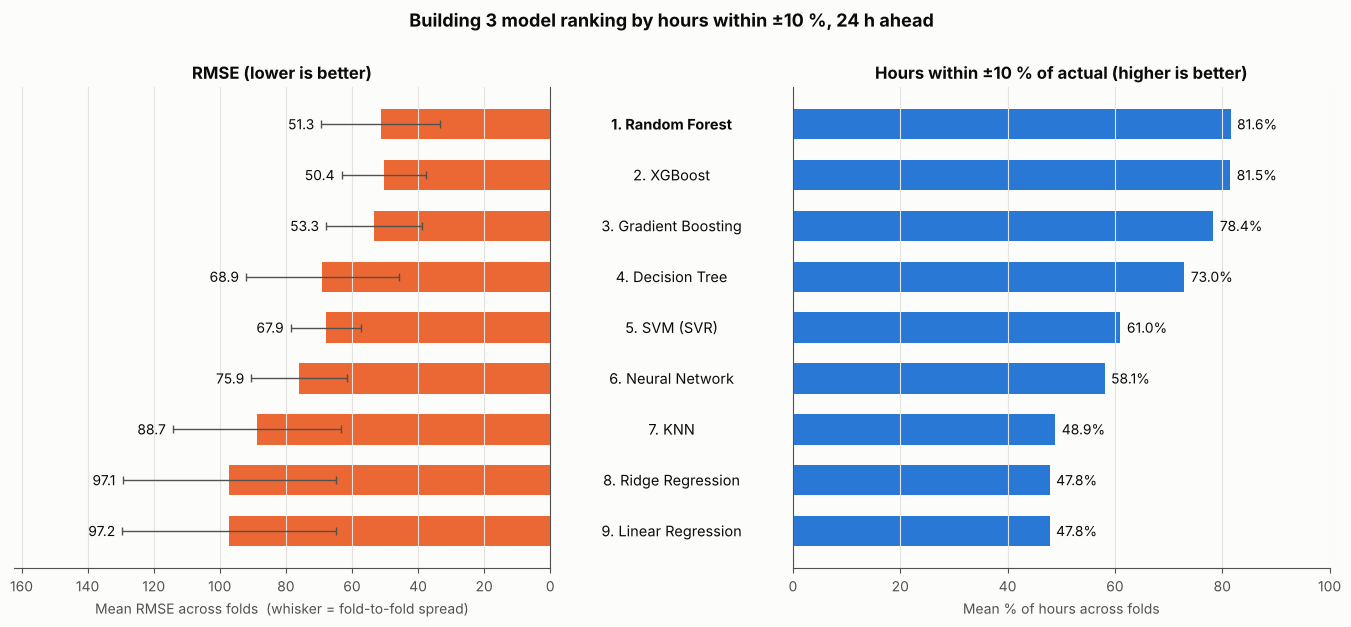

In [10]:
ranking = (model_cv.groupby("Model")[["Within_10pct", "RMSE", "MAE", "R2"]].mean()
           .join(model_cv.groupby("Model")[["Within_10pct", "RMSE"]].std().add_suffix("_std")))
ranking = ranking.sort_values(["Within_10pct", "RMSE"], ascending=[False, True])
ranking.insert(0, "Rank", range(1, len(ranking) + 1))

display(ranking[["Rank", "Within_10pct", "Within_10pct_std", "RMSE", "RMSE_std", "MAE", "R2"]].round(2))
ranking.to_csv(OUTPUT_DIR / "model_ranking.csv")
model_cv.to_csv(OUTPUT_DIR / "walkforward_cv_models_by_fold.csv", index=False)
BEST_MODEL = ranking.index[0]
print(f"Best model by hours within ±10 %: {BEST_MODEL}")

# ---- Chart: one ranking, both measures as bars (RMSE left, within ±10 % right) ----
labels = [f"{r}. {m}" for r, m in zip(ranking["Rank"], ranking.index)]
y = np.arange(len(ranking))
RMSE_COLOR, W10_COLOR = ORANGE, BLUE

fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.42, 1], wspace=0.02)
ax_r = fig.add_subplot(gs[0])
ax_lab = fig.add_subplot(gs[1], sharey=ax_r)
ax_w = fig.add_subplot(gs[2], sharey=ax_r)

# Left: RMSE (bars grow to the left, lower is better)
rmse_max = (ranking["RMSE"] + ranking["RMSE_std"]).max() * 1.12
ax_r.barh(y, ranking["RMSE"], xerr=ranking["RMSE_std"], color=RMSE_COLOR, height=0.6,
          error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 3})
for yi, (v, s) in enumerate(zip(ranking["RMSE"], ranking["RMSE_std"])):
    ax_r.text(v + s + rmse_max * 0.015, yi, f"{v:.1f}", va="center", ha="right", color=INK, fontsize=10)
ax_r.set_xlim(rmse_max * 1.12, 0)
ax_r.set_title("RMSE (lower is better)", color=INK)
ax_r.set_xlabel("Mean RMSE across folds  (whisker = fold-to-fold spread)")
ax_r.tick_params(axis="y", left=False, labelleft=False)
ax_r.spines["left"].set_visible(False); ax_r.spines["right"].set_visible(True)

# Middle: model names, ranked by hours within ±10 %
ax_lab.set_xlim(0, 1); ax_lab.axis("off")
for yi, lab in enumerate(labels):
    ax_lab.text(0.5, yi, lab, ha="center", va="center", color=INK, fontsize=10.5,
                fontweight="bold" if yi == 0 else "normal")

# Right: hours within ±10 % (higher is better)
ax_w.barh(y, ranking["Within_10pct"], color=W10_COLOR, height=0.6)
for yi, v in enumerate(ranking["Within_10pct"]):
    ax_w.text(v + 1.2, yi, f"{v:.1f}%", va="center", color=INK, fontsize=10)
ax_w.set_xlim(0, 100)
ax_w.set_title("Hours within ±10 % of actual (higher is better)", color=INK)
ax_w.set_xlabel("Mean % of hours across folds")
ax_w.tick_params(axis="y", left=False, labelleft=False)

ax_r.invert_yaxis()
for ax in (ax_r, ax_w):
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Building 3 model ranking by hours within ±10 %, {HORIZON_HOURS} h ahead",
             fontweight="bold", color=INK, fontsize=13)
fig.subplots_adjust(left=0.03, right=0.97, top=0.86, bottom=0.12)
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=160); plt.show()

## 8. Tune XGBoost

XGBoost is tuned with a random search. To keep the test scores honest, tuning uses **only data from before the first test window**:
* the earlier 80 % of that period is used for training;
* the later 20 % is used for validation.

Early stopping picks the number of trees. The chosen settings are then re-scored on all walk-forward folds, so the tuned model is compared on exactly the same footing as everything else.

In [11]:
rng = np.random.default_rng(RANDOM_STATE)
SEARCH_SPACE = {
    "max_depth": [3, 4, 5, 6, 7, 8],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10, 20],
    "reg_lambda": [0.5, 1.0, 3.0, 10.0],
}
N_TRIALS = 25

pre_test = data.iloc[: FOLDS[0][1][0]]
cut = int(len(pre_test) * 0.8)
tune_tr, tune_val = pre_test.iloc[:cut], pre_test.iloc[cut:]
print(f"Tuning train: {tune_tr.index.min().date()} -> {tune_tr.index.max().date()}  |  "
      f"validation: {tune_val.index.min().date()} -> {tune_val.index.max().date()}")

trials = []
for t in range(N_TRIALS):
    params = {k: rng.choice(v).item() for k, v in SEARCH_SPACE.items()}
    m = XGBRegressor(n_estimators=3000, early_stopping_rounds=100, tree_method="hist",
                     random_state=RANDOM_STATE, n_jobs=-1, **params)
    m.fit(tune_tr[FEATURES], tune_tr["usage"], eval_set=[(tune_val[FEATURES], tune_val["usage"])], verbose=False)
    rmse = mean_squared_error(tune_val["usage"], m.predict(tune_val[FEATURES])) ** 0.5
    trials.append({**params, "n_estimators": m.best_iteration + 1, "val_RMSE": rmse})

trials = pd.DataFrame(trials).sort_values("val_RMSE")
display(trials.head(5).round(3))
best = trials.iloc[0].drop("val_RMSE").to_dict()
BEST_PARAMS = {k: (int(v) if k in ("max_depth", "n_estimators", "min_child_weight") else float(v)) for k, v in best.items()}
print("Chosen XGBoost settings:", BEST_PARAMS)

Tuning train: 2016-03-08 -> 2018-05-20  |  validation: 2018-05-20 -> 2018-12-06


,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,n_estimators,val_RMSE
3,8,0.03,0.8,0.6,1,10.0,748,46.630
14,6,0.05,0.6,0.6,10,10.0,839,46.685
8,7,0.08,0.9,0.5,3,1.0,426,46.689
13,6,0.05,1.0,0.7,1,10.0,676,46.732
2,7,0.08,0.9,0.8,5,0.5,303,47.069


Chosen XGBoost settings: {'max_depth': 8, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.6, 'min_child_weight': 1, 'reg_lambda': 10.0, 'n_estimators': 748}


In [12]:
def make_tuned_xgb():
    return XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)


def walk_forward(features, label):
    rows, preds = [], []
    for i, (tr, te) in enumerate(FOLDS, 1):
        m = make_tuned_xgb().fit(data[features].iloc[tr], data["usage"].iloc[tr])
        p = m.predict(data[features].iloc[te])
        rows.append({"Model": label, "Fold": i, **score(data["usage"].iloc[te], p)})
        preds.append(pd.Series(p, index=data.index[te]))
    return pd.DataFrame(rows), pd.concat(preds)


tuned_cv, tuned_oof = walk_forward(FEATURES, "XGBoost (tuned)")
compare = pd.concat([model_cv[model_cv["Model"] == "XGBoost"], tuned_cv])
display(compare.groupby("Model")[["MAE", "RMSE", "R2", "Within_10pct"]].agg(["mean", "std"]).round(2))
display(tuned_cv.round(2))

MAE         RMSE           R2       Within_10pct      
                  mean   std   mean    std  mean   std         mean   std
Model                                                                    
XGBoost          32.04  8.27  50.41  12.69  0.95  0.02        81.49  7.03
XGBoost (tuned)  32.09  8.66  49.41  13.70  0.95  0.02        80.96  8.30

,Model,Fold,MAE,RMSE,R2,MAPE_pct,Within_10pct
0,XGBoost (tuned),1,41.68,63.21,0.95,7.45,75.71
1,XGBoost (tuned),2,26.02,39.95,0.97,4.84,89.71
2,XGBoost (tuned),3,29.57,48.85,0.96,5.93,85.91
3,XGBoost (tuned),4,40.65,62.74,0.92,8.68,69.28
4,XGBoost (tuned),5,22.51,32.31,0.93,6.09,84.19


## 9. How accurate is the model?

Every number below is measured on the walk-forward test windows. The model never saw those hours during training, so they reflect how it would perform on genuinely new data.

**Skill score** = 1 − RMSE(model) / RMSE(best naive baseline). It answers: *how much of the naive forecast's error does the model remove?* 0 means no better than the baseline; 0.3 means 30 % less error.

In [13]:
y_oof = data["usage"].reindex(tuned_oof.index)
final_scores = score(y_oof, tuned_oof)

baseline_means = baseline_cv.groupby("Model")["RMSE"].mean()
best_baseline = baseline_means.idxmin()
fold_skill = 1 - tuned_cv["RMSE"].to_numpy() / baseline_cv[baseline_cv["Model"] == best_baseline]["RMSE"].to_numpy()
mean_demand = y_oof.mean()

headline = pd.DataFrame({
    "Metric": ["Mean absolute error (MAE)", "MAE as % of average demand", "Root mean squared error (RMSE)",
               "R²", "Hours within ±10 % of actual", f"Skill vs '{best_baseline}'"],
    "Value": [f"{final_scores['MAE']:.1f}", f"{final_scores['MAE'] / mean_demand * 100:.1f} %",
              f"{final_scores['RMSE']:.1f}", f"{final_scores['R2']:.3f}",
              f"{final_scores['Within_10pct']:.1f} %",
              f"{fold_skill.mean():.2f} (range {fold_skill.min():.2f} to {fold_skill.max():.2f} across folds)"],
})
display(headline)

,Metric,Value
0,Mean absolute error (MAE),32.1
1,MAE as % of average demand,6.6 %
2,Root mean squared error (RMSE),50.9
3,R²,0.956
4,Hours within ±10 % of actual,81.0 %
5,"Skill vs 'Same hour, recent weeks'",0.41 (range -0.13 to 0.60 across folds)


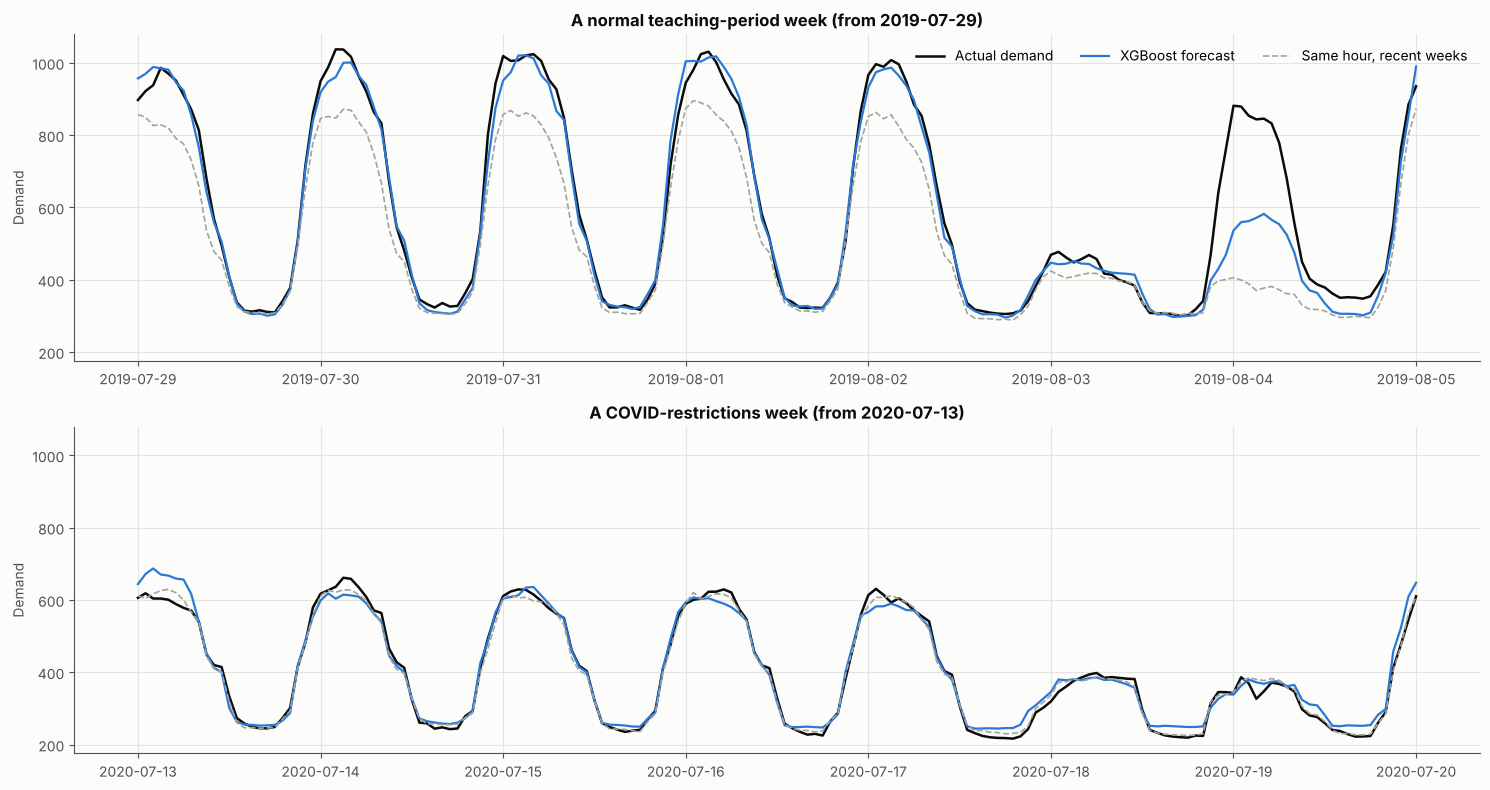

In [14]:
covid_start = pd.Timestamp("2020-03-16")


def plot_week(start, title, ax):
    end = pd.Timestamp(start) + pd.Timedelta(days=7)
    a = y_oof.loc[start:end]
    p = tuned_oof.loc[start:end]
    b = baseline_oof[best_baseline].loc[start:end]
    ax.plot(a.index, a, color=INK, linewidth=1.8, label="Actual demand")
    ax.plot(p.index, p, color=BLUE, linewidth=1.6, label="XGBoost forecast")
    ax.plot(b.index, b, color=BASELINE_GREY, linewidth=1.2, linestyle="--", label=best_baseline)
    ax.set_title(title); ax.set_ylabel("Demand")


test_idx = tuned_oof.index
pre = test_idx[(test_idx < covid_start) & (test_idx.dayofweek == 0) & (test_idx.hour == 0)]
post = test_idx[(test_idx >= covid_start + pd.Timedelta(days=30)) & (test_idx.dayofweek == 0) & (test_idx.hour == 0)]
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharey=True)
if len(pre):
    plot_week(pre[len(pre) // 2], f"A normal teaching-period week (from {pre[len(pre) // 2].date()})", axes[0])
if len(post):
    plot_week(post[len(post) // 2], f"A COVID-restrictions week (from {post[len(post) // 2].date()})", axes[1])
axes[0].legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "actual_vs_forecast_weeks.png", dpi=160); plt.show()

### Where does the model make mistakes?

These breakdowns are worth including in a report. They show *when* the forecast is reliable and when it is not, which matters more to a reader than a single overall score.

,MAE,RMSE,R2,MAPE_pct,Within_10pct
period,,,,,
COVID (from 16 Mar 2020),31.31,49.90,0.87,7.90,74.69
Pre-COVID,32.42,51.33,0.96,6.04,83.65


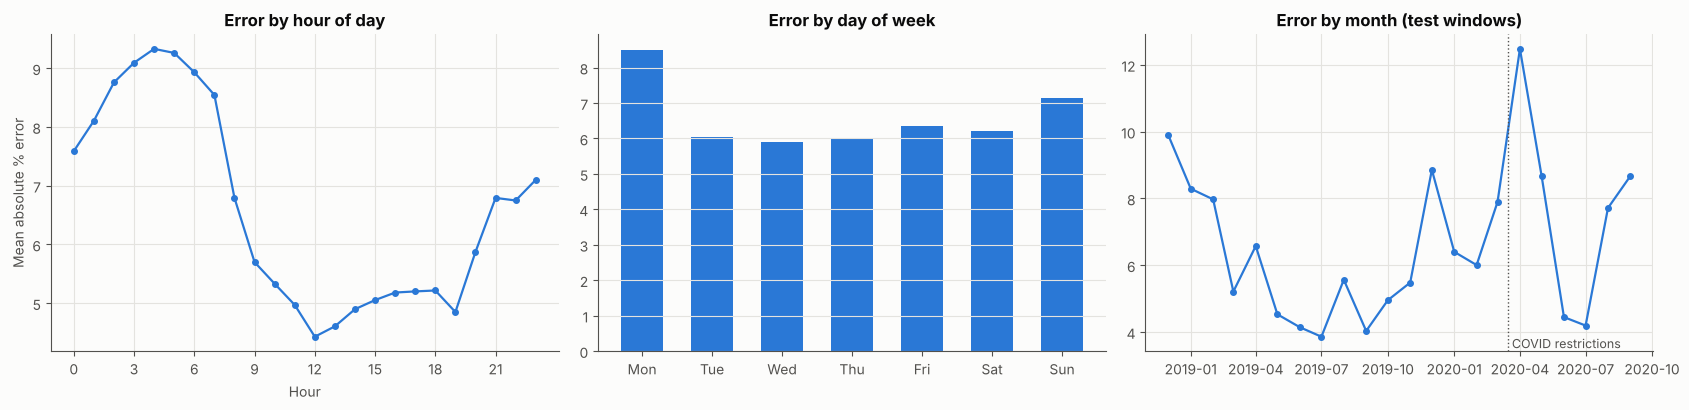

In [15]:
err = pd.DataFrame({"actual": y_oof, "pred": tuned_oof})
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["pct_err"] = err["abs_err"] / err["actual"] * 100
err["period"] = np.where(err.index >= covid_start, "COVID (from 16 Mar 2020)", "Pre-COVID")

period_table = err.groupby("period").apply(lambda g: pd.Series(score(g["actual"], g["pred"]))).round(2)
display(period_table)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
by_hour = err.groupby(err.index.hour)["pct_err"].mean()
axes[0].plot(by_hour.index, by_hour.values, color=BLUE, marker="o", markersize=4)
axes[0].set_title("Error by hour of day"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Mean absolute % error")
axes[0].set_xticks(range(0, 24, 3))

by_dow = err.groupby(err.index.dayofweek)["pct_err"].mean()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_dow.values, color=BLUE, width=0.6)
axes[1].set_title("Error by day of week"); axes[1].grid(axis="x", visible=False)

by_month = err["pct_err"].resample("MS").mean()
axes[2].plot(by_month.index, by_month.values, color=BLUE, marker="o", markersize=4)
axes[2].axvline(covid_start, color=INK_2, linestyle=":", linewidth=1)
axes[2].text(covid_start, axes[2].get_ylim()[0], " COVID restrictions", color=INK_2, fontsize=9, va="bottom")
axes[2].set_title("Error by month (test windows)")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "error_breakdown.png", dpi=160); plt.show()

## 10. Prediction intervals (uncertainty)

A single number hides uncertainty. Here each forecast gets an **80 % interval** using split-conformal prediction:
1. Take the model's percentage errors on *earlier* test windows.
2. Use the 10th and 90th percentiles of those errors to widen each new forecast into a band.
3. Check on the *next* window how often the actual value really fell inside the band.

If the bands work, coverage should be close to 80 %. Errors are measured as a percentage because demand swings between about 150 and 1,500 units, and errors grow with the size of the demand.

In [16]:
INTERVAL = 0.80
lo_q, hi_q = (1 - INTERVAL) / 2, 1 - (1 - INTERVAL) / 2
rel_resid = ((y_oof - tuned_oof) / tuned_oof)

cov_rows = []
for i in range(1, len(FOLDS)):
    past_idx = data.index[np.concatenate([FOLDS[j][1] for j in range(i)])]
    now_idx = data.index[FOLDS[i][1]]
    q_lo, q_hi = rel_resid.loc[past_idx].quantile([lo_q, hi_q])
    lo, hi = tuned_oof.loc[now_idx] * (1 + q_lo), tuned_oof.loc[now_idx] * (1 + q_hi)
    inside = (y_oof.loc[now_idx] >= lo) & (y_oof.loc[now_idx] <= hi)
    cov_rows.append({"Fold": i + 1, "coverage_pct": inside.mean() * 100,
                     "avg_band_width": (hi - lo).mean(), "band": f"{q_lo * 100:+.1f}% to {q_hi * 100:+.1f}%"})

coverage = pd.DataFrame(cov_rows)
display(coverage.round(1))
print(f"Average coverage of the {INTERVAL:.0%} interval: {coverage['coverage_pct'].mean():.1f} %")

Q_LO, Q_HI = rel_resid.quantile([lo_q, hi_q])     # used for the final forecast

,Fold,coverage_pct,avg_band_width,band
0,2,91.7,120.900002,-11.1% to +11.1%
1,3,83.4,94.000000,-9.2% to +9.2%
2,4,66.1,84.900002,-9.0% to +8.7%
3,5,86.8,76.000000,-11.2% to +8.3%


Average coverage of the 80% interval: 82.0 %


## 11. How much does the forecast rely on weather?

ERA5 is observed weather. In a real forecast you would only have a weather *forecast*, which is less accurate. Re-running the tuned model **without any weather features** gives a lower bound:
* if accuracy barely drops, the model does not depend on weather being perfect;
* if it drops a lot, a real deployment would need good weather forecasts.

In [17]:
no_weather_features = [c for c in FEATURES if c not in WEATHER_FEATURES]
nw_cv, nw_oof = walk_forward(no_weather_features, "XGBoost (tuned, no weather)")
weather_table = pd.concat([tuned_cv, nw_cv]).groupby("Model")[["MAE", "RMSE", "R2", "Within_10pct"]].mean().round(2)
display(weather_table)

,MAE,RMSE,R2,Within_10pct
Model,,,,
XGBoost (tuned),32.09,49.41,0.95,80.96
"XGBoost (tuned, no weather)",36.43,55.96,0.94,76.55


## 12. Explaining the model

**What it is.** XGBoost builds hundreds of small decision trees one after another. Each new tree learns to correct the errors left by the trees before it. The final forecast is the sum of all the trees' outputs.

**Which inputs matter.** SHAP values split each forecast into the contribution of every input:
* The bar chart ranks features by their average impact.
* The beeswarm shows direction. Red dots are high feature values; a dot to the right means that value pushed the forecast *up*.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


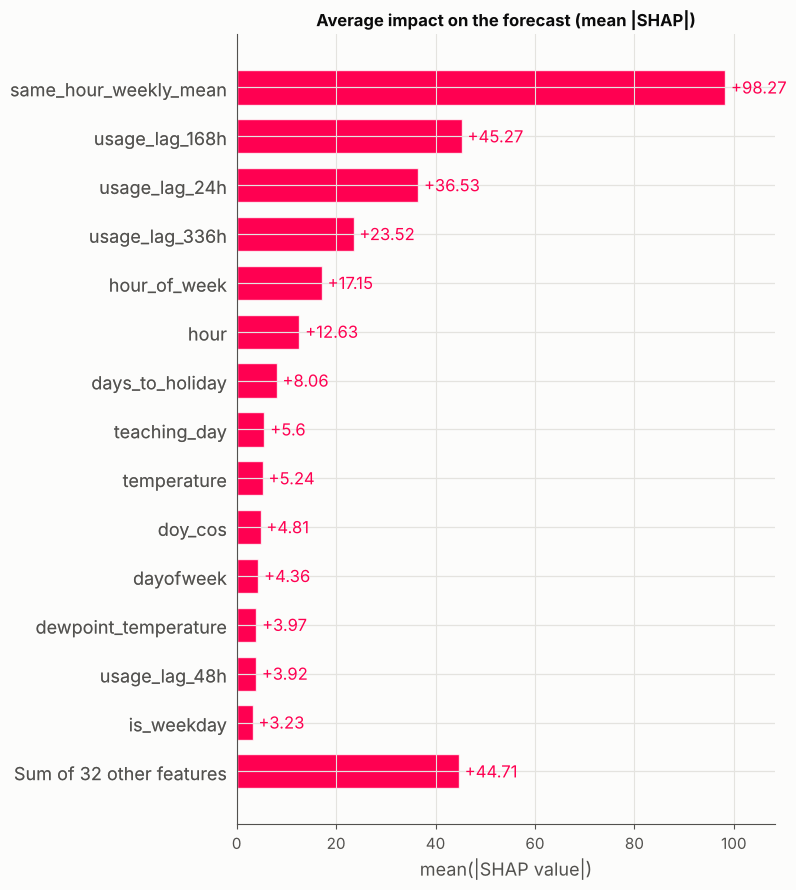

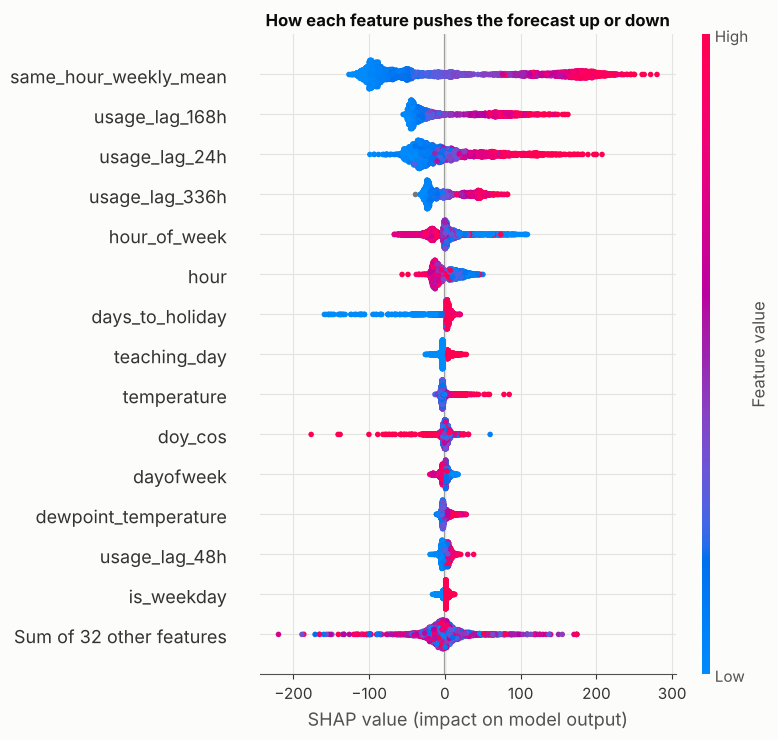

,importance
same_hour_weekly_mean,98.269997
usage_lag_168h,45.270000
usage_lag_24h,36.529999
usage_lag_336h,23.520000
hour_of_week,17.150000
hour,12.630000
days_to_holiday,8.060000
teaching_day,5.600000
temperature,5.240000
doy_cos,4.810000


In [18]:
final_model = make_tuned_xgb().fit(data[FEATURES], data["usage"])

try:
    import shap
    sample = data[FEATURES].sample(min(3000, len(data)), random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer(sample)
    shap.plots.bar(shap_values, max_display=15, show=False)
    plt.title("Average impact on the forecast (mean |SHAP|)"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "shap_importance.png", dpi=160); plt.show()
    shap.plots.beeswarm(shap_values, max_display=15, show=False)
    plt.title("How each feature pushes the forecast up or down"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "shap_beeswarm.png", dpi=160); plt.show()
    importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
except ImportError:
    print("shap is not installed (pip install shap) - showing XGBoost gain importance instead.")
    importance = pd.Series(final_model.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)
    importance = importance.sort_values(ascending=False)
    importance.head(15)[::-1].plot.barh(color=BLUE, figsize=(9, 6)); plt.title("XGBoost gain importance"); plt.show()

display(importance.head(15).round(2).to_frame("importance"))

## 13. Final model and forecast for the next horizon

The tuned model is retrained on **all** cleaned data and saved. It then forecasts the next `HORIZON_HOURS` hours after the last observation, with the 80 % band from Section 10.

For a day-ahead model, this produces the forecast for 1 October 2020.

,forecast,lower_80,upper_80
2020-10-01 00:00:00,442.100006,392.799988,476.500000
2020-10-01 01:00:00,457.500000,406.399994,493.100006
2020-10-01 02:00:00,465.000000,413.100006,501.200012
2020-10-01 03:00:00,469.500000,417.000000,506.000000
2020-10-01 04:00:00,462.299988,410.700012,498.299988
2020-10-01 05:00:00,447.200012,397.200012,482.000000
2020-10-01 06:00:00,455.000000,404.200012,490.399994
2020-10-01 07:00:00,443.700012,394.100006,478.200012
2020-10-01 08:00:00,421.399994,374.399994,454.200012
2020-10-01 09:00:00,357.600006,317.600006,385.399994


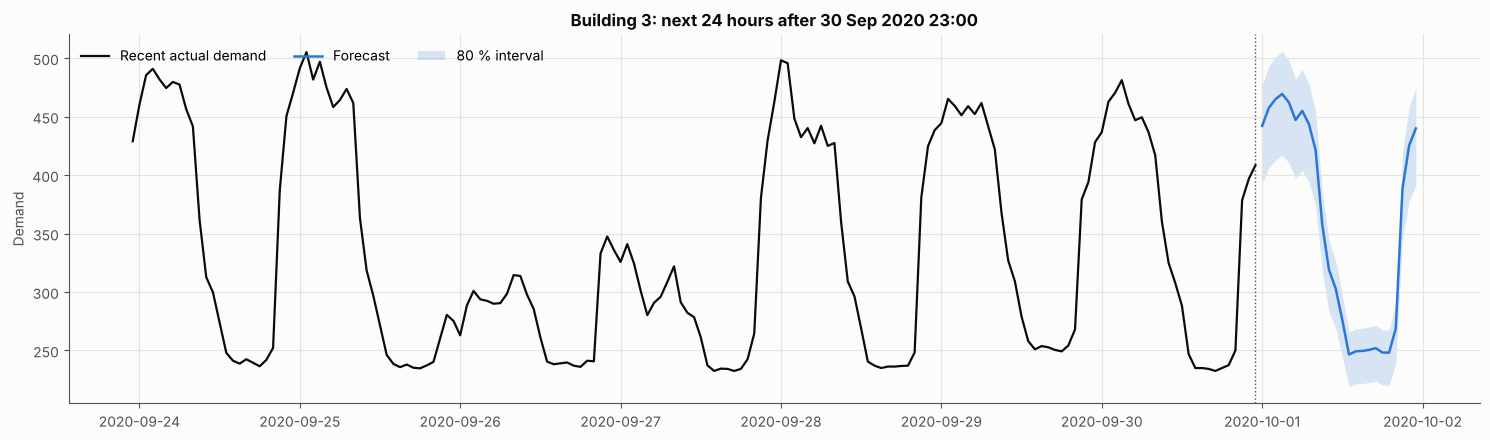

In [19]:
from joblib import dump

dump({"model": final_model, "features": FEATURES, "params": BEST_PARAMS, "horizon_hours": HORIZON_HOURS,
      "interval": (float(Q_LO), float(Q_HI))}, OUTPUT_DIR / f"{BUILDING}_xgb_h{HORIZON_HOURS}.joblib")

last_obs = usage.dropna().index.max()
future_index = pd.date_range(last_obs + pd.Timedelta(hours=1), periods=HORIZON_HOURS, freq="h")
future_X = build_table(usage, calendar, weather, HORIZON_HOURS, future_index)[FEATURES]
forecast = pd.DataFrame({"forecast": final_model.predict(future_X)}, index=future_index)
forecast["lower_80"] = forecast["forecast"] * (1 + Q_LO)
forecast["upper_80"] = forecast["forecast"] * (1 + Q_HI)
forecast.to_csv(OUTPUT_DIR / f"{BUILDING}_forecast_next_{HORIZON_HOURS}h.csv")
display(forecast.round(1).head(24))

history = usage.loc[last_obs - pd.Timedelta(days=7):last_obs]
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(history.index, history, color=INK, linewidth=1.6, label="Recent actual demand")
ax.plot(forecast.index, forecast["forecast"], color=BLUE, linewidth=1.8, label="Forecast")
ax.fill_between(forecast.index, forecast["lower_80"], forecast["upper_80"], color=BLUE, alpha=0.18,
                linewidth=0, label="80 % interval")
ax.axvline(last_obs, color=INK_2, linestyle=":", linewidth=1)
ax.set_title(f"Building 3: next {HORIZON_HOURS} hours after {last_obs:%d %b %Y %H:%M}")
ax.set_ylabel("Demand"); ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "next_horizon_forecast.png", dpi=160); plt.show()